# Procesamiento de Lenguaje Natural I
## Desafío 4 — Traductor Seq2Seq

**Lourdes Tolotto** 

### Objetivo

Se replica el traductor inglés → español desarrollado en clase con una arquitectura **Encoder–Decoder Seq2Seq basada en LSTM** y *teacher forcing*.

Para extender el experimento se realizan los siguientes cambios:

- Se aumenta el conjunto de entrenamiento de **10.000 a 30.000 pares de oraciones**.
- Se permiten secuencias más largas: **30 tokens de entrada y 32 de salida**, frente a 20/22 del ejemplo de clase.
- Se comparan tres configuraciones de las capas recurrentes: **128, 256 y 512 unidades LSTM**.
- Se mantienen fijos el resto de los hiperparámetros principales para que la comparación se concentre en el número de unidades recurrentes.
- Se comparan *loss*, *accuracy*, cantidad de parámetros y tiempo de entrenamiento.
- Para el mejor modelo se calcula **BLEU** y se muestran al menos cinco traducciones.
- Como actividad opcional sencilla, al final se incorpora **sampling con temperatura**.


### 1. Librerías y configuración

In [1]:
import os
import gc
import time
import pickle
import zipfile
import urllib.request
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.layers import Input, LSTM, Dense, Embedding, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.metrics import SparseCategoricalAccuracy

from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

SEED = 40
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU disponible: []


### 2. Dataset

Se utiliza el mismo corpus paralelo inglés–español del ejemplo de clase (`spa-eng`), pero se amplía el número de pares utilizados.

In [2]:
DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip"
ZIP_PATH = "spa-eng.zip"
DATA_PATH = "./spa-eng/spa.txt"

if not os.path.exists(DATA_PATH):
    if not os.path.exists(ZIP_PATH):
        urllib.request.urlretrieve(DATA_URL, ZIP_PATH)

    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(".")

with open(DATA_PATH, encoding="utf-8") as f:
    lines = [line for line in f.read().splitlines() if "\t" in line]

print(f"Pares disponibles en el corpus: {len(lines):,}")

Pares disponibles en el corpus: 118,964


### 3. Preparación de los datos

El notebook de clase utiliza 10.000 oraciones, `max_input_len=20` y `max_out_len=22`.

En este desafío se aumenta el corpus a **30.000 pares** y las longitudes máximas a **30/32 tokens**. Además, se separa un conjunto de test que no se utiliza durante el entrenamiento.

In [3]:
MAX_NUM_SENTENCES = 30_000
MAX_VOCAB_SIZE = 8_000

MAX_INPUT_LEN = 30
MAX_OUTPUT_LEN = 32

BATCH_SIZE = 64
EPOCHS = 20
UNITS_TO_TEST = [128, 256, 512]

DROPOUT = 0.3
LEARNING_RATE = 5e-4

rng = np.random.default_rng(SEED)
rng.shuffle(lines)

pairs = []
for line in lines[:MAX_NUM_SENTENCES]:
    parts = line.rstrip().split("\t")
    if len(parts) >= 2:
        pairs.append((parts[0], parts[1]))

n = len(pairs)
n_train = int(0.80 * n)
n_val = int(0.10 * n)

train_pairs = pairs[:n_train]
val_pairs = pairs[n_train:n_train + n_val]
test_pairs = pairs[n_train + n_val:]

train_en = [x for x, _ in train_pairs]
train_es = [y for _, y in train_pairs]

val_en = [x for x, _ in val_pairs]
val_es = [y for _, y in val_pairs]

test_en = [x for x, _ in test_pairs]
test_es = [y for _, y in test_pairs]

print(f"Train: {len(train_pairs):,}")
print(f"Validación: {len(val_pairs):,}")
print(f"Test: {len(test_pairs):,}")

Train: 24,000
Validación: 3,000
Test: 3,000


#### Tokenización

Se ajustan los tokenizadores **solo con el conjunto de entrenamiento**.  
Para el decoder se conservan los tokens especiales `<sos>` y `<eos>` necesarios para iniciar y finalizar la traducción.

In [4]:
input_tokenizer = Tokenizer(
    num_words=MAX_VOCAB_SIZE,
    oov_token="<unk>"
)
input_tokenizer.fit_on_texts(train_en)

target_train_in = ["<sos> " + s for s in train_es]
target_train_out = [s + " <eos>" for s in train_es]

output_tokenizer = Tokenizer(
    num_words=MAX_VOCAB_SIZE,
    oov_token="<unk>",
    filters='!"#$%&()*+,-./:;=¿?@[\\]^_`{|}~\t\n'
)
output_tokenizer.fit_on_texts(target_train_in + target_train_out)

word2idx_inputs = input_tokenizer.word_index
word2idx_outputs = output_tokenizer.word_index

nb_words = min(MAX_VOCAB_SIZE, len(word2idx_inputs) + 1)
num_words_output = min(MAX_VOCAB_SIZE, len(word2idx_outputs) + 1)

print(f"Vocabulario EN utilizado: {nb_words:,}")
print(f"Vocabulario ES utilizado: {num_words_output:,}")
print("ID <sos>:", word2idx_outputs["<sos>"])
print("ID <eos>:", word2idx_outputs["<eos>"])

Vocabulario EN utilizado: 7,402
Vocabulario ES utilizado: 8,000
ID <sos>: 2
ID <eos>: 3


In [5]:
def vectorize_split(en_sentences, es_sentences):
    input_seq = input_tokenizer.texts_to_sequences(en_sentences)
    decoder_in_seq = output_tokenizer.texts_to_sequences(
        ["<sos> " + s for s in es_sentences]
    )
    decoder_out_seq = output_tokenizer.texts_to_sequences(
        [s + " <eos>" for s in es_sentences]
    )

    encoder = pad_sequences(
        input_seq,
        maxlen=MAX_INPUT_LEN,
        padding="post",
        truncating="post"
    )
    decoder_in = pad_sequences(
        decoder_in_seq,
        maxlen=MAX_OUTPUT_LEN,
        padding="post",
        truncating="post"
    )
    decoder_out = pad_sequences(
        decoder_out_seq,
        maxlen=MAX_OUTPUT_LEN,
        padding="post",
        truncating="post"
    )

    # Los tokens de padding (0) no deben aportar al loss ni al accuracy.
    weights = (decoder_out != 0).astype("float32")

    return encoder, decoder_in, decoder_out, weights


enc_train, dec_in_train, dec_out_train, w_train = vectorize_split(train_en, train_es)
enc_val, dec_in_val, dec_out_val, w_val = vectorize_split(val_en, val_es)
enc_test, dec_in_test, dec_out_test, w_test = vectorize_split(test_en, test_es)

train_input_lengths = [
    len(seq) for seq in input_tokenizer.texts_to_sequences(train_en)
]
train_output_lengths = [
    len(seq) for seq in output_tokenizer.texts_to_sequences(target_train_out)
]

print("Longitud máxima observada EN:", max(train_input_lengths))
print("Longitud máxima observada ES:", max(train_output_lengths))
print(
    "Entradas con más de 20 tokens:",
    sum(length > 20 for length in train_input_lengths)
)
print(
    "Salidas con más de 22 tokens:",
    sum(length > 22 for length in train_output_lengths)
)
print("Shapes:", enc_train.shape, dec_in_train.shape, dec_out_train.shape)

Longitud máxima observada EN: 34
Longitud máxima observada ES: 36
Entradas con más de 20 tokens: 18
Salidas con más de 22 tokens: 15
Shapes: (24000, 30) (24000, 32) (24000, 32)


### 4. Embeddings GloVe del encoder

Se conserva la estrategia del notebook de clase: el encoder utiliza embeddings GloVe preentrenados de 50 dimensiones y sus pesos se mantienen congelados.

El decoder aprende sus embeddings durante el entrenamiento.

In [6]:
GLOVE_PATH = "gloveembedding.pkl"
GLOVE_FILE_ID = "1KY6avD5I1eI2dxQzMkR3WExwKwRq2g94"
EMBED_DIM = 50
DECODER_EMBED_DIM = 128

if not os.path.exists(GLOVE_PATH):
    try:
        import gdown
    except ImportError:
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", "gdown"]
        )
        import gdown

    print("Descargando embeddings GloVe...")
    gdown.download(id=GLOVE_FILE_ID, output=GLOVE_PATH, quiet=False)

print("Archivo GloVe disponible:", os.path.exists(GLOVE_PATH))

Descargando embeddings GloVe...


Downloading...
From (original): https://drive.google.com/uc?id=1KY6avD5I1eI2dxQzMkR3WExwKwRq2g94
From (redirected): https://drive.google.com/uc?id=1KY6avD5I1eI2dxQzMkR3WExwKwRq2g94&confirm=t&uuid=af44b834-6355-4b24-abf7-adf7745166b9
To: c:\Users\tolot\Documents\UBA\2026\uba-ai-master\nlp\gloveembedding.pkl
100%|██████████| 525M/525M [00:19<00:00, 27.4MB/s] 

Archivo GloVe disponible: True


In [7]:
def load_glove_embeddings(pkl_path):
    # Se mantiene el método del notebook de clase para cargar el pickle.
    max_bytes = 2**28 - 1
    raw = bytearray()
    size = os.path.getsize(pkl_path)

    with open(pkl_path, "rb") as f:
        for _ in range(0, size, max_bytes):
            raw += f.read(max_bytes)

    embeddings = pickle.loads(raw)
    idx_array = np.arange(embeddings.shape[0])
    word2idx = dict(zip(embeddings["word"], idx_array))

    return embeddings, word2idx


def get_word_embedding(word, embeddings, word2idx, n_features=50):
    i = word2idx.get(word, -1)
    if i == -1:
        return np.zeros(n_features)
    return embeddings[i]["embedding"]


def build_embedding_matrix(
    tokenizer_word_index,
    embeddings,
    glove_word2idx,
    vocab_size,
    embed_dim=50
):
    matrix = np.zeros((vocab_size, embed_dim))

    for word, i in tokenizer_word_index.items():
        if i < vocab_size:
            matrix[i] = get_word_embedding(
                word,
                embeddings,
                glove_word2idx,
                embed_dim
            )

    return matrix


glove_embeddings, glove_word2idx = load_glove_embeddings(GLOVE_PATH)

embedding_matrix = build_embedding_matrix(
    word2idx_inputs,
    glove_embeddings,
    glove_word2idx,
    nb_words,
    EMBED_DIM
)

n_zero = np.sum(np.sum(embedding_matrix**2, axis=1) == 0)
print(f"Embeddings sin vector GloVe: {n_zero:,} / {nb_words:,}")

Embeddings sin vector GloVe: 348 / 7,402


### 5. Modelo Seq2Seq

Para estudiar específicamente el impacto del número de neuronas recurrentes:

- Se prueban **128, 256 y 512 unidades LSTM**.
- El embedding del decoder queda fijo en 128 dimensiones.
- Se mantiene el mismo dropout, learning rate, corpus y longitud de secuencia para los tres experimentos.

De esta manera, la principal variable que cambia entre modelos es la capacidad de las capas recurrentes.

In [8]:
def build_seq2seq_model(n_units):
    # -----------------
    # Encoder
    # -----------------
    encoder_inputs = Input(
        shape=(MAX_INPUT_LEN,),
        dtype="int32",
        name="encoder_inputs"
    )

    encoder_embedding = Embedding(
        input_dim=nb_words,
        output_dim=EMBED_DIM,
        weights=[embedding_matrix],
        trainable=False,
        mask_zero=True,
        name="encoder_embedding"
    )

    x = encoder_embedding(encoder_inputs)
    x = Dropout(DROPOUT, name="encoder_dropout")(x)

    encoder_lstm = LSTM(
        n_units,
        return_state=True,
        name="encoder_lstm"
    )

    _, state_h, state_c = encoder_lstm(x)
    encoder_states = [state_h, state_c]

    # -----------------
    # Decoder
    # -----------------
    decoder_inputs = Input(
        shape=(MAX_OUTPUT_LEN,),
        dtype="int32",
        name="decoder_inputs"
    )

    decoder_embedding = Embedding(
        input_dim=num_words_output,
        output_dim=DECODER_EMBED_DIM,
        mask_zero=True,
        name="decoder_embedding"
    )

    x = decoder_embedding(decoder_inputs)
    x = Dropout(DROPOUT, name="decoder_dropout")(x)

    decoder_lstm = LSTM(
        n_units,
        return_sequences=True,
        return_state=True,
        name="decoder_lstm"
    )

    decoder_outputs, _, _ = decoder_lstm(
        x,
        initial_state=encoder_states
    )

    decoder_dense = Dense(
        num_words_output,
        activation="softmax",
        name="decoder_dense"
    )

    decoder_outputs = decoder_dense(decoder_outputs)

    model = Model(
        [encoder_inputs, decoder_inputs],
        decoder_outputs
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss=SparseCategoricalCrossentropy(),
        weighted_metrics=[
            SparseCategoricalAccuracy(name="accuracy")
        ]
    )

    return model


def make_callbacks():
    return [
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-5,
            verbose=1
        ),
        EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True,
            verbose=1
        )
    ]

### 6. Entrenamiento y comparación

Los tres modelos se entrenan bajo las mismas condiciones.  
El mejor modelo se selecciona según el **menor `val_loss`**, sin utilizar el conjunto de test para esa decisión.

In [9]:
results = []
histories = {}

best_val_loss_global = np.inf
best_units = None
BEST_MODEL_PATH = "best_seq2seq_model.keras"

for n_units in UNITS_TO_TEST:
    print("\n" + "=" * 70)
    print(f"Entrenando modelo con {n_units} unidades LSTM")
    print("=" * 70)

    tf.keras.backend.clear_session()
    gc.collect()

    model = build_seq2seq_model(n_units)
    n_params = model.count_params()

    start = time.time()

    history = model.fit(
        [enc_train, dec_in_train],
        dec_out_train,
        sample_weight=w_train,
        validation_data=(
            [enc_val, dec_in_val],
            dec_out_val,
            w_val
        ),
        batch_size=BATCH_SIZE,
        epochs=EPOCHS,
        callbacks=make_callbacks(),
        verbose=1
    )

    elapsed = time.time() - start

    test_loss, test_accuracy = model.evaluate(
        [enc_test, dec_in_test],
        dec_out_test,
        sample_weight=w_test,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    min_val_loss = float(np.min(history.history["val_loss"]))
    best_val_accuracy = float(np.max(history.history["val_accuracy"]))

    results.append({
        "LSTM units": n_units,
        "Parámetros": n_params,
        "Épocas": len(history.history["loss"]),
        "Mejor val_loss": min_val_loss,
        "Mejor val_accuracy": best_val_accuracy,
        "Test loss": float(test_loss),
        "Test accuracy": float(test_accuracy),
        "Tiempo (min)": elapsed / 60
    })

    histories[n_units] = history.history

    # Se guarda solamente el mejor modelo para no ocupar espacio innecesario.
    if min_val_loss < best_val_loss_global:
        best_val_loss_global = min_val_loss
        best_units = n_units
        model.save(BEST_MODEL_PATH)
        print(f"Nuevo mejor modelo guardado: {n_units} unidades")

    del model
    gc.collect()

results_df = pd.DataFrame(results).sort_values("LSTM units")
results_df


Entrenando modelo con 128 unidades LSTM

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 316s 817ms/step - accuracy: 0.1326 - loss: 6.1469 - val_accuracy: 0.1620 - val_loss: 5.4551 - learning_rate: 5.0000e-04
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 205s 544ms/step - accuracy: 0.1781 - loss: 5.5218 - val_accuracy: 0.2011 - val_loss: 5.1847 - learning_rate: 5.0000e-04
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 165s 286ms/step - accuracy: 0.2059 - loss: 5.2557 - val_accuracy: 0.2301 - val_loss: 4.9301 - learning_rate: 5.0000e-04
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 123s 327ms/step - accuracy: 0.2356 - loss: 5.0058 - val_accuracy: 0.2553 - val_loss: 4.7130 - learning_rate: 5.0000e-04
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 63s 169ms/step - accuracy: 0.2535 - loss: 4.7948 - val_accuracy: 0.2673 - val_loss: 4.5381 - learning_rate: 5.0000e-04
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 61s 162ms/step - accuracy: 0.2645 - loss: 4.6154 - val_accuracy: 0.2794 - val_loss: 4.3879 - learning_rate: 5.0000e-04


,LSTM units,Parámetros,Épocas,Mejor val_loss,Mejor val_accuracy,Test loss,Test accuracy,Tiempo (min)
0,128,2649332,20,3.407216,0.379501,3.443647,0.376050,30.139821
1,256,4158708,20,3.068673,0.420433,3.115921,0.416760,33.437328
2,512,7963892,20,2.806570,0.464413,2.874504,0.460131,57.212182


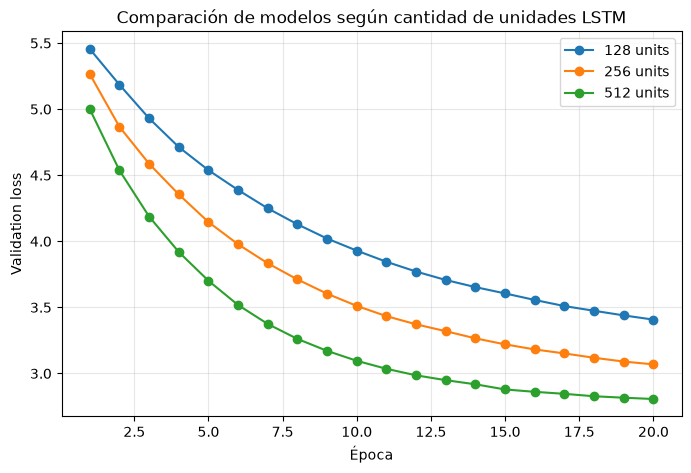

Mejor configuración según val_loss: 512 unidades


In [10]:
plt.figure(figsize=(8, 5))

for units, history in histories.items():
    epochs = range(1, len(history["val_loss"]) + 1)
    plt.plot(epochs, history["val_loss"], marker="o", label=f"{units} units")

plt.xlabel("Época")
plt.ylabel("Validation loss")
plt.title("Comparación de modelos según cantidad de unidades LSTM")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Mejor configuración según val_loss: {best_units} unidades")

### 7. Inferencia con el mejor modelo

Durante el entrenamiento se utiliza *teacher forcing*.  
Para inferencia, el decoder genera un token por vez a partir de `<sos>` hasta producir `<eos>` o alcanzar la longitud máxima.

In [11]:
best_model = tf.keras.models.load_model(
    BEST_MODEL_PATH,
    compile=False
)

idx2word_target = {
    idx: word
    for word, idx in word2idx_outputs.items()
    if idx < num_words_output
}

SOS_ID = word2idx_outputs["<sos>"]
EOS_ID = word2idx_outputs["<eos>"]


def build_inference_models(trained_model, n_units):
    # Encoder de inferencia
    enc_input = Input(
        shape=(MAX_INPUT_LEN,),
        dtype="int32",
        name="encoder_input_inference"
    )

    enc_embedding_layer = trained_model.get_layer("encoder_embedding")
    enc_lstm_layer = trained_model.get_layer("encoder_lstm")

    enc_x = enc_embedding_layer(enc_input)
    _, h, c = enc_lstm_layer(enc_x)

    encoder_model = Model(enc_input, [h, c])

    # Decoder de inferencia: un token por paso
    token_input = Input(
        shape=(1,),
        dtype="int32",
        name="decoder_token_inference"
    )
    h_input = Input(shape=(n_units,), name="decoder_h_inference")
    c_input = Input(shape=(n_units,), name="decoder_c_inference")

    dec_embedding_layer = trained_model.get_layer("decoder_embedding")
    dec_lstm_layer = trained_model.get_layer("decoder_lstm")
    dec_dense_layer = trained_model.get_layer("decoder_dense")

    dec_x = dec_embedding_layer(token_input)

    dec_output, h_out, c_out = dec_lstm_layer(
        dec_x,
        initial_state=[h_input, c_input]
    )

    probabilities = dec_dense_layer(dec_output)

    decoder_model = Model(
        [token_input, h_input, c_input],
        [probabilities, h_out, c_out]
    )

    return encoder_model, decoder_model


encoder_model, decoder_model = build_inference_models(
    best_model,
    best_units
)

In [12]:
def greedy_decode_batch(encoder_sequences, batch_size=128):
    h, c = encoder_model.predict(
        encoder_sequences,
        batch_size=batch_size,
        verbose=0
    )

    n_samples = len(encoder_sequences)
    current_token = np.full(
        (n_samples, 1),
        SOS_ID,
        dtype=np.int32
    )

    generated = np.zeros(
        (n_samples, MAX_OUTPUT_LEN),
        dtype=np.int32
    )

    finished = np.zeros(n_samples, dtype=bool)

    for t in range(MAX_OUTPUT_LEN):
        probs, h, c = decoder_model.predict(
            [current_token, h, c],
            batch_size=batch_size,
            verbose=0
        )

        step_probs = probs[:, 0, :].copy()

        # PAD y <sos> no son tokens válidos como salida.
        step_probs[:, 0] = -1.0
        step_probs[:, SOS_ID] = -1.0

        next_token = np.argmax(step_probs, axis=-1).astype(np.int32)

        # Las secuencias terminadas permanecen en <eos>.
        next_token = np.where(finished, EOS_ID, next_token)

        generated[:, t] = next_token
        finished |= (next_token == EOS_ID)

        current_token = next_token[:, None]

        if finished.all():
            break

    return generated


def ids_to_tokens(ids):
    tokens = []

    for idx in ids:
        idx = int(idx)

        if idx == EOS_ID:
            break

        if idx in (0, SOS_ID):
            continue

        word = idx2word_target.get(idx)
        if word is not None:
            tokens.append(word)

    return tokens


def translate(text):
    seq = input_tokenizer.texts_to_sequences([text])
    seq = pad_sequences(
        seq,
        maxlen=MAX_INPUT_LEN,
        padding="post",
        truncating="post"
    )

    pred_ids = greedy_decode_batch(seq, batch_size=1)[0]
    return " ".join(ids_to_tokens(pred_ids))

#### Métrica BLEU

Además de `loss` y `accuracy`, se calcula BLEU sobre una muestra del conjunto de test.  
Se informan **BLEU-1** y **BLEU-4** para complementar la evaluación token a token con una métrica orientada a la secuencia traducida.

In [13]:
BLEU_SAMPLES = min(500, len(enc_test))

pred_test_ids = greedy_decode_batch(
    enc_test[:BLEU_SAMPLES],
    batch_size=128
)

references = []
hypotheses = []

for ref_ids, pred_ids in zip(
    dec_out_test[:BLEU_SAMPLES],
    pred_test_ids
):
    ref_tokens = ids_to_tokens(ref_ids)
    pred_tokens = ids_to_tokens(pred_ids)

    references.append([ref_tokens])
    hypotheses.append(pred_tokens)

smooth = SmoothingFunction().method1

bleu_1 = corpus_bleu(
    references,
    hypotheses,
    weights=(1.0, 0, 0, 0),
    smoothing_function=smooth
)

bleu_4 = corpus_bleu(
    references,
    hypotheses,
    weights=(0.25, 0.25, 0.25, 0.25),
    smoothing_function=smooth
)

print(f"BLEU-1 ({BLEU_SAMPLES} ejemplos): {bleu_1:.4f}")
print(f"BLEU-4 ({BLEU_SAMPLES} ejemplos): {bleu_4:.4f}")

BLEU-1 (500 ejemplos): 0.3763
BLEU-4 (500 ejemplos): 0.0905


#### Cinco ejemplos de traducción

Se usan ejemplos del conjunto de **test**, es decir, oraciones que no fueron utilizadas para entrenar el modelo.

In [14]:
example_rng = np.random.default_rng(SEED)
example_indices = example_rng.choice(
    len(test_en),
    size=5,
    replace=False
)

example_sequences = enc_test[example_indices]
example_predictions = greedy_decode_batch(
    example_sequences,
    batch_size=5
)

for idx, pred_ids in zip(example_indices, example_predictions):
    print("EN:       ", test_en[idx])
    print("ES real:  ", test_es[idx])
    print("ES modelo:", " ".join(ids_to_tokens(pred_ids)))
    print("-" * 80)

EN:        Is that so?
ES real:   ¿Es así?
ES modelo: es eso
--------------------------------------------------------------------------------
EN:        Tom had drunk too much coffee so he couldn't sleep.
ES real:   Tom tomó mucho café así que no pudo dormir.
ES modelo: tom tenía demasiado atractivo cuando yo no estaba demasiado cansado
--------------------------------------------------------------------------------
EN:        I've been here since Monday.
ES real:   Llevo aquí desde el lunes.
ES modelo: he estado aquí desde hace tarde
--------------------------------------------------------------------------------
EN:        I never worry.
ES real:   Yo nunca me preocupo.
ES modelo: nunca dudé
--------------------------------------------------------------------------------
EN:        Do you want to dance?
ES real:   ¿Querés bailar?
ES modelo: querés bailar
--------------------------------------------------------------------------------


### 8. Opcional — Sampling con temperatura

Como extensión sencilla se agrega una estrategia de generación estocástica.  
A diferencia de greedy search, que siempre elige el token más probable, el sampling permite seleccionar tokens de acuerdo con su distribución de probabilidad.

- **Temperatura < 1:** generación más conservadora.
- **Temperatura ≈ 1:** mantiene la distribución original.
- **Temperatura > 1:** aumenta la diversidad, pero también el riesgo de errores.

Esta es una sección complementaria y no interviene en la comparación principal de los modelos.

In [15]:
def sample_token(probabilities, temperature=1.0):
    probabilities = np.asarray(probabilities, dtype=np.float64)

    probabilities[0] = 0.0
    probabilities[SOS_ID] = 0.0

    log_probs = np.log(np.clip(probabilities, 1e-12, 1.0))
    log_probs = log_probs / temperature

    probs = np.exp(log_probs - np.max(log_probs))
    probs = probs / probs.sum()

    return np.random.choice(len(probs), p=probs)


def translate_sampling(text, temperature=1.0):
    seq = input_tokenizer.texts_to_sequences([text])
    seq = pad_sequences(
        seq,
        maxlen=MAX_INPUT_LEN,
        padding="post",
        truncating="post"
    )

    h, c = encoder_model.predict(seq, verbose=0)

    current_token = np.array([[SOS_ID]], dtype=np.int32)
    output_tokens = []

    for _ in range(MAX_OUTPUT_LEN):
        probs, h, c = decoder_model.predict(
            [current_token, h, c],
            verbose=0
        )

        next_id = sample_token(
            probs[0, 0, :],
            temperature=temperature
        )

        if next_id == EOS_ID:
            break

        if next_id > 0:
            word = idx2word_target.get(next_id)
            if word is not None:
                output_tokens.append(word)

        current_token[0, 0] = next_id

    return " ".join(output_tokens)


example_text = "Can you help me?"

print("Greedy:", translate(example_text))

for temp in [0.5, 1.0, 1.5]:
    print(
        f"Sampling T={temp}:",
        translate_sampling(example_text, temperature=temp)
    )

Greedy: puedes ayudarme
Sampling T=0.5: puedes ayudarme
Sampling T=1.0: puedes ayudarme
Sampling T=1.5: quieres ayudarme


### Conclusiones

En este trabajo se implementó un traductor inglés-español basado en una arquitectura Seq2Seq Encoder-Decoder con capas LSTM. A partir del modelo visto en clase se amplió el conjunto de datos a 30.000 pares de oraciones y se aumentó la longitud máxima de las secuencias, además de comparar configuraciones con 128, 256 y 512 unidades recurrentes.

Los resultados muestran una mejora consistente al aumentar la cantidad de unidades LSTM. El modelo de 128 unidades obtuvo un `val_loss` de 3.41 y una accuracy de validación de 0.38, mientras que con 256 unidades estos valores mejoraron a 3.07 y 0.42. La mejor configuración fue la de 512 unidades, con un `val_loss` de 2.81 y una accuracy de validación de 0.46. En el conjunto de test mantuvo un comportamiento similar, alcanzando una accuracy de 0.46 y un `test_loss` de 2.87.

Esta mejora tuvo como contrapartida un aumento considerable en el costo computacional. El modelo pasó de aproximadamente 2.6 millones de parámetros con 128 unidades a casi 8 millones con 512 unidades. El tiempo de entrenamiento también aumentó, llegando a unos 57 minutos para el modelo más grande frente a aproximadamente 30 minutos para el de 128 unidades. Por lo tanto, en este caso aumentar la capacidad del modelo mejoró el desempeño, aunque con un costo mayor de memoria y tiempo de entrenamiento.

Para evaluar la calidad de las secuencias generadas también se calculó BLEU sobre 500 ejemplos del conjunto de test. Se obtuvo un BLEU-1 de 0.3763 y un BLEU-4 de 0.0905. La diferencia entre ambas métricas muestra que el modelo logra acertar una proporción razonable de palabras individuales, pero todavía presenta dificultades para generar secuencias completas de palabras que coincidan con las traducciones de referencia.

Los ejemplos de traducción reflejan esta situación. En frases simples el modelo puede generar traducciones muy cercanas a la referencia, como *"Do you want to dance?" → "querés bailar"*. En otros casos conserva parcialmente el significado, por ejemplo *"I've been here since Monday." → "he estado aquí desde hace tarde"*, pero comete errores en palabras importantes. En oraciones más largas, como la relacionada con haber tomado demasiado café, la traducción pierde gran parte del significado original. Estos ejemplos sugieren que el modelo presenta mayores dificultades a medida que aumenta la longitud o complejidad de la oración.
Como prueba adicional se incorporó sampling con temperatura. Para la frase *"Can you help me?"*, greedy search y temperaturas de 0.5 y 1.0 generaron *"puedes ayudarme"*, mientras que con temperatura 1.5 se obtuvo *"quieres ayudarme"*. En este ejemplo se observa que aumentar la temperatura introduce mayor variabilidad, aunque esa diversidad no implica necesariamente una mejor traducción.

En general, el aumento de unidades recurrentes permitió mejorar de forma clara el modelo, pero las traducciones obtenidas también muestran las limitaciones del enfoque Seq2Seq clásico. El encoder debe condensar toda la oración de entrada en sus estados finales, lo que puede dificultar la conservación de información en secuencias más largas. Como posibles mejoras podrían incorporarse mecanismos de atención o arquitecturas Transformer, que permiten manejar de forma más directa las relaciones entre distintas partes de la secuencia.